# 02 · Exploratory Data Analysis
Understanding the candidate pool before building the matching engine:
who the candidates are, what skills they have, how experience and exposure differ by domain,
and whether some patterns are statistically significant.

In [1]:
# --- Setup -----------------------------------------------------------
# Add the project root folder to the Python path so "src" can be imported
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Standard libraries for data handling and charts
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # hide library warnings so the output stays readable
pd.set_option("display.max_columns", 60)   # show all columns when printing a dataframe
pd.set_option("display.max_colwidth", 80)  # do not cut long text too early

# Project settings: file paths, colours and the chart style
from src.config import *
from src.plot_style import set_style, save
set_style()

In [2]:
# Load the cleaned data from notebook 01 (list columns are rebuilt automatically)
from src.cleaning import load_cleaned, SKILL_TO_FAMILY
df = load_cleaned(CLEANED_FILE)
print(df.shape)

(5000, 44)


## 1. Who is in the candidate pool?

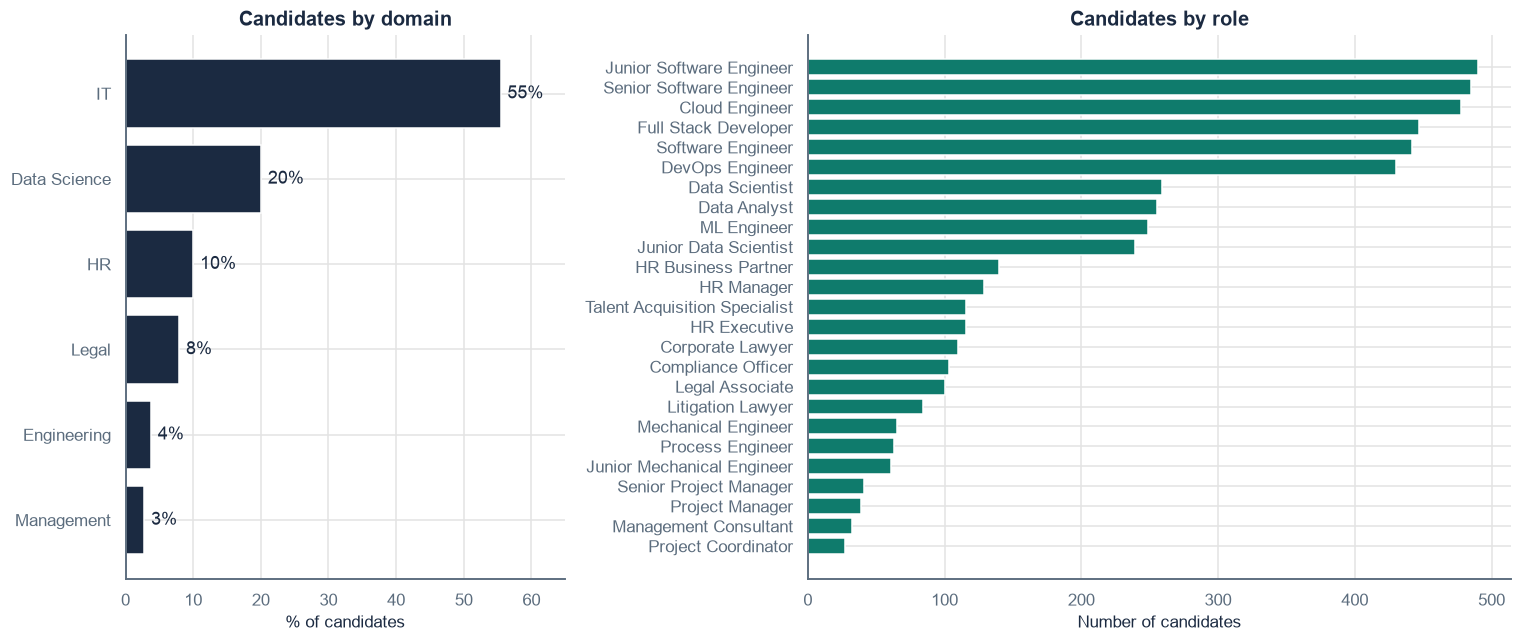

In [3]:
# Count candidates per domain and per role
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.6]})

dom = df["primary_domain"].value_counts(normalize=True).sort_values()
axes[0].barh(dom.index, dom.values * 100, color=COLORS["ink"])
for i, v in enumerate(dom.values):
    axes[0].text(v * 100 + 1, i, f"{v:.0%}", va="center", color=COLORS["ink"])   # % label at the end of each bar
axes[0].set_xlim(0, 65)
axes[0].set_xlabel("% of candidates")
axes[0].set_title("Candidates by domain")

role = df["primary_role"].value_counts()
axes[1].barh(role.index[::-1], role.values[::-1], color=COLORS["teal"])
axes[1].set_title("Candidates by role")
axes[1].set_xlabel("Number of candidates")
fig.tight_layout()
save(fig, "02_domain_role")
plt.show()

IT dominates (55%), followed by Data Science (20%). HR, Legal, Engineering and Management are much smaller pools,
so for those roles **every good candidate matters** — a keyword filter that misses them is costly.

## 2. Experience and seniority

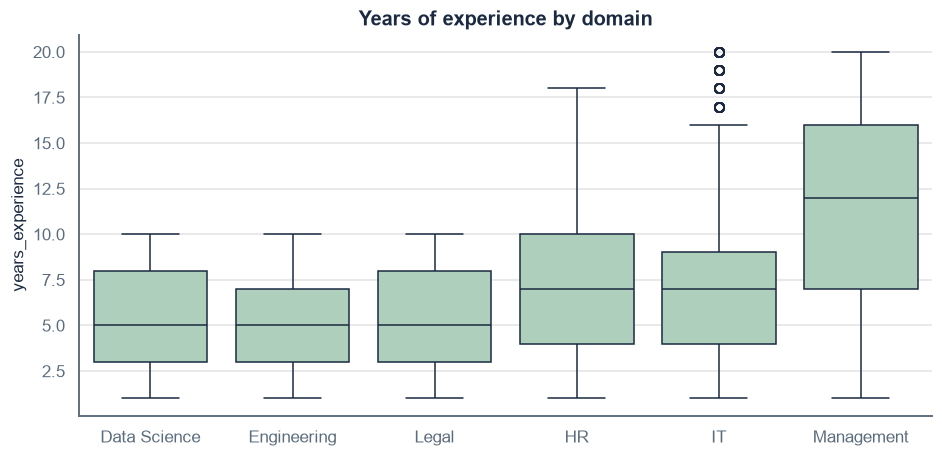

In [4]:
# Box plot of years of experience for each domain
order = df.groupby("primary_domain")["years_experience"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="primary_domain", y="years_experience", order=order, ax=ax,
            color=COLORS["mint"], linecolor=COLORS["ink"])
ax.set_title("Years of experience by domain")
ax.set_xlabel("")
save(fig, "02_experience_by_domain")
plt.show()

In [5]:
# Seniority level (read from the job title) vs experience bucket
from src.features import experience_bucket
df["experience_bucket"] = df["years_experience"].apply(experience_bucket)
pd.crosstab(df["seniority_level"], df["experience_bucket"])[
    ["Entry (0-2)", "Mid (3-5)", "Senior (6-10)", "Expert (11+)"]]

experience_bucket,Entry (0-2),Mid (3-5),Senior (6-10),Expert (11+)
seniority_level,,,,
Junior,528,505,0,0
Mid,0,1175,2066,0
Senior,0,0,193,533


Seniority titles line up cleanly with experience — juniors have ≤ 4 years, seniors ≥ 6 — so experience is a reliable seniority signal.

## 3. Education and institution tier

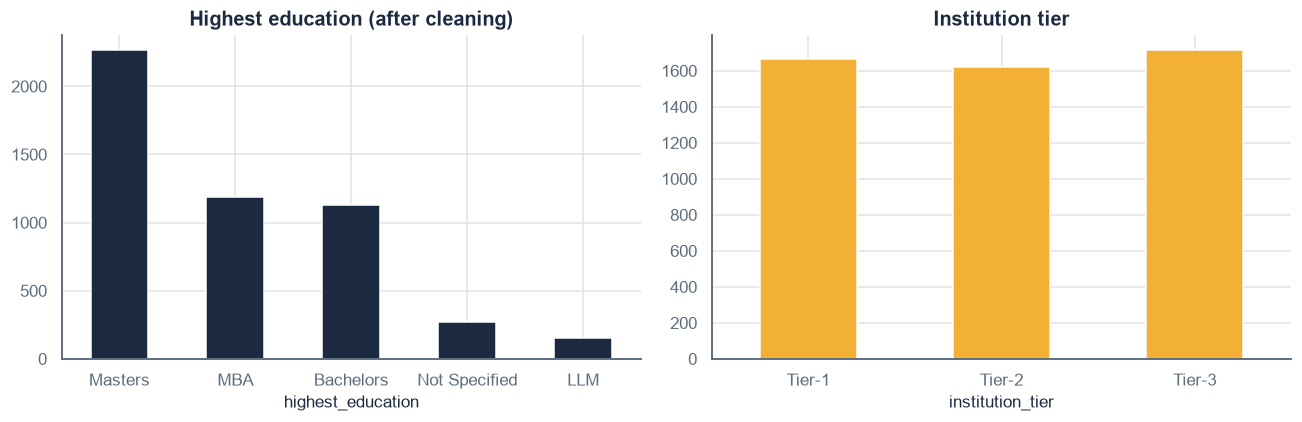

In [6]:
# Education level and institution tier side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["highest_education"].value_counts().plot.bar(ax=axes[0], color=COLORS["ink"])
axes[0].set_title("Highest education (after cleaning)")
df["institution_tier"].value_counts().sort_index().plot.bar(ax=axes[1], color=COLORS["mustard"])
axes[1].set_title("Institution tier")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
save(fig, "02_education_tier")
plt.show()

## 4. Skills landscape

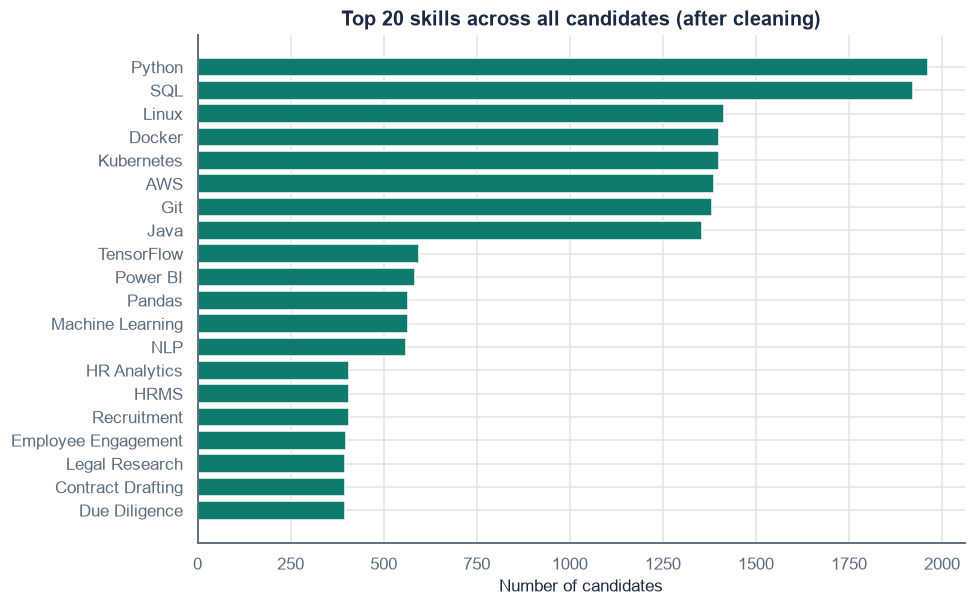

In [7]:
# Explode the skill lists so each (candidate, skill) is one row
skills_long = df[["candidate_id", "primary_domain", "skills_clean"]].explode("skills_clean")

top = skills_long["skills_clean"].value_counts().head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index[::-1], top.values[::-1], color=COLORS["teal"])
ax.set_title("Top 20 skills across all candidates (after cleaning)")
ax.set_xlabel("Number of candidates")
save(fig, "02_top_skills")
plt.show()

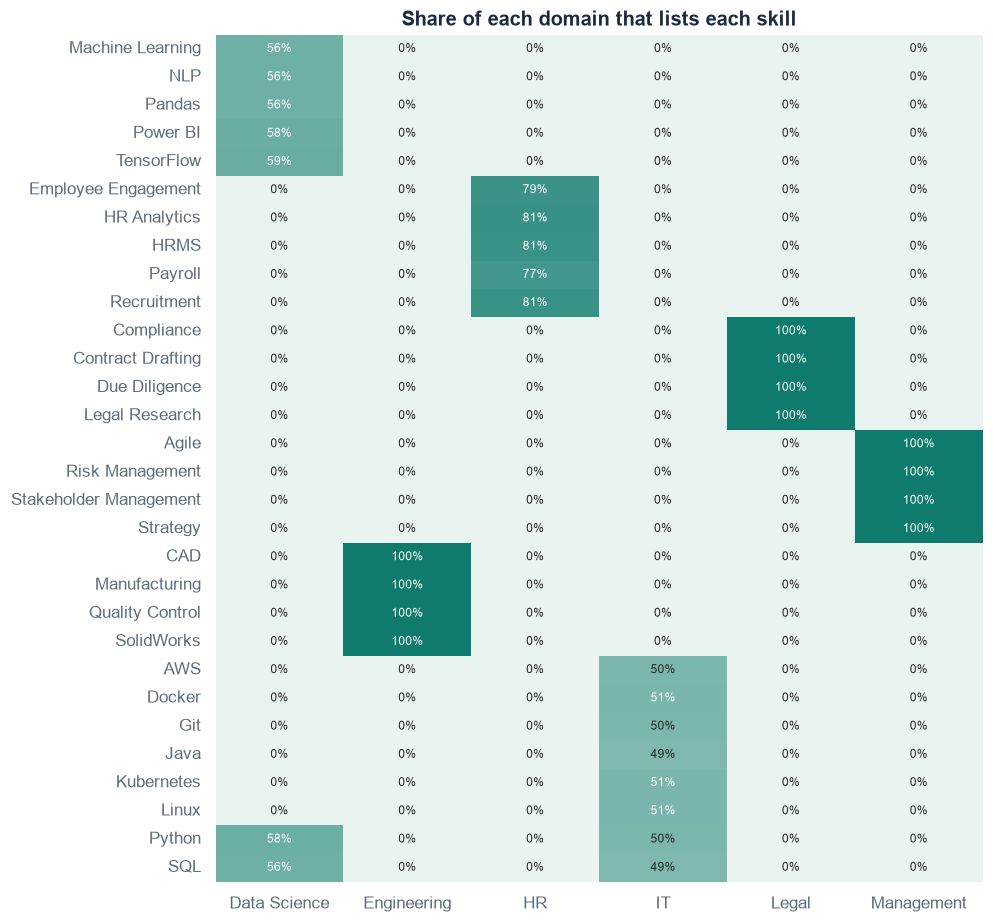

In [8]:
# Heatmap: share of candidates in each domain that list each skill
share = pd.crosstab(skills_long["skills_clean"], skills_long["primary_domain"])
share = share.div(df["primary_domain"].value_counts(), axis=1)
# order skills by family so the blocks are easy to see
share = share.loc[sorted(share.index, key=lambda s: (SKILL_TO_FAMILY.get(s, "z"), s))]

fig, ax = plt.subplots(figsize=(9, 10))
sns.heatmap(share, cmap=sns.light_palette(COLORS["teal"], as_cmap=True), annot=True, fmt=".0%",
            cbar=False, ax=ax, annot_kws={"size": 8})
ax.set_title("Share of each domain that lists each skill")
ax.set_xlabel("")
ax.set_ylabel("")
save(fig, "02_skill_domain_heatmap")
plt.show()

**Insight:** skills form clear blocks by domain — IT candidates draw from 8 software/cloud skills, Data Science from
ML/analytics skills plus Python/SQL, and the other domains have their own small skill sets. Inside IT every candidate
lists only 4 of the 8 skills, so *which* 4 they list is what separates a good fit for a specific job.

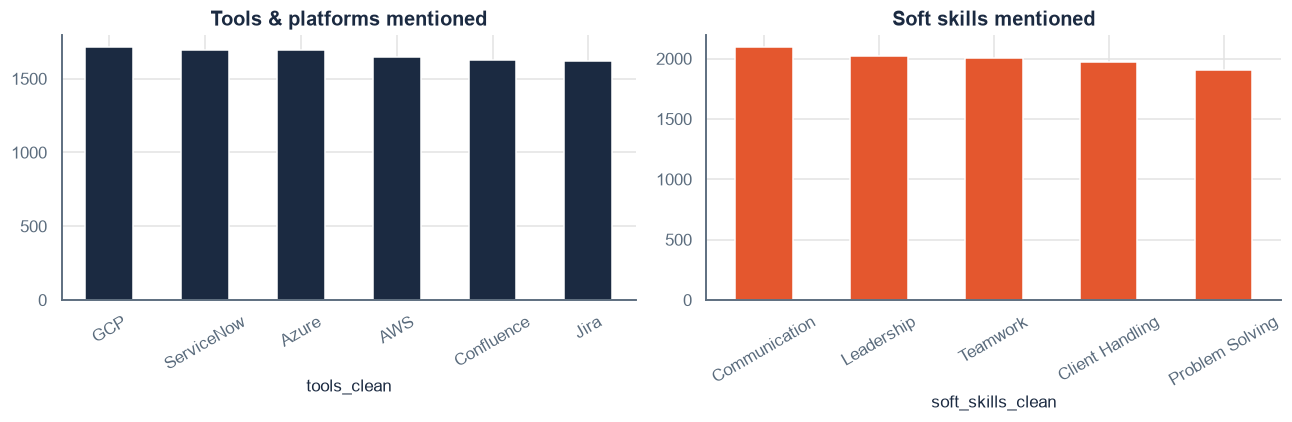

In [9]:
# Tools / platforms and soft skills
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["tools_clean"].explode().value_counts().plot.bar(ax=axes[0], color=COLORS["ink"])
axes[0].set_title("Tools & platforms mentioned")
df["soft_skills_clean"].explode().value_counts().plot.bar(ax=axes[1], color=COLORS["coral"])
axes[1].set_title("Soft skills mentioned")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
save(fig, "02_tools_soft")
plt.show()

## 5. Experience exposure flags by domain

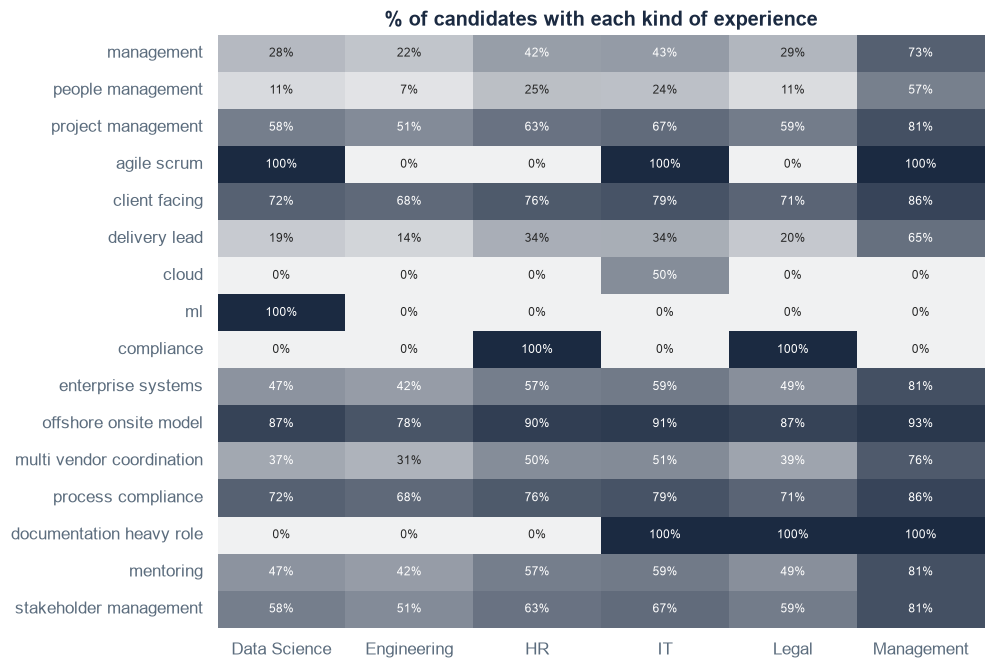

In [10]:
# Average of each yes/no flag per domain (= % of candidates with that exposure)
flag_cols = [c for c in df.columns if c.endswith("_flag") and c not in
             ("education_missing_flag", "education_corrected_flag", "skill_typo_flag")]
flag_means = df.groupby("primary_domain")[flag_cols].mean().T
flag_means.index = [c.replace("_experience_flag", "").replace("_flag", "").replace("_", " ") for c in flag_means.index]

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(flag_means, cmap=sns.light_palette(COLORS["ink"], as_cmap=True), annot=True, fmt=".0%",
            cbar=False, ax=ax, annot_kws={"size": 8})
ax.set_title("% of candidates with each kind of experience")
ax.set_xlabel("")
save(fig, "02_flags_by_domain")
plt.show()

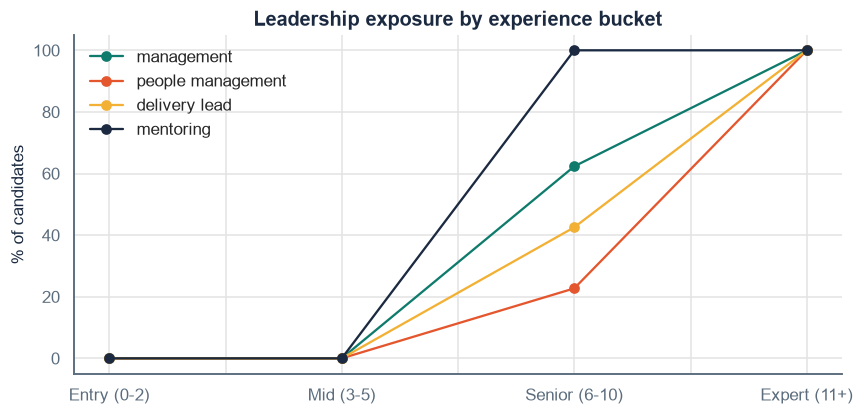

In [11]:
# Leadership exposure grows with years of experience?
lead_cols = ["management_experience_flag", "people_management_flag", "delivery_lead_experience_flag", "mentoring_experience_flag"]
by_bucket = df.groupby("experience_bucket")[lead_cols].mean().loc[["Entry (0-2)", "Mid (3-5)", "Senior (6-10)", "Expert (11+)"]]

fig, ax = plt.subplots(figsize=(9, 4))
by_bucket.mul(100).plot(ax=ax, marker="o", color=[COLORS["teal"], COLORS["coral"], COLORS["mustard"], COLORS["ink"]])
ax.set_ylabel("% of candidates")
ax.set_xlabel("")
ax.set_title("Leadership exposure by experience bucket")
ax.legend([c.replace("_experience_flag", "").replace("_flag", "").replace("_", " ") for c in lead_cols], frameon=False)
save(fig, "02_leadership_by_experience")
plt.show()

## 6. Text analysis of experience summaries

In [12]:
# Most important words per domain using TF-IDF (words that are frequent in one domain but rare in others)
from sklearn.feature_extraction.text import TfidfVectorizer

domain_docs = df.groupby("primary_domain")["experience_summary_clean"].apply(" ".join)
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), token_pattern=r"[a-z]{3,}")
mat = vec.fit_transform(domain_docs)
terms = np.array(vec.get_feature_names_out())

top_terms = {dom: ", ".join(terms[mat[i].toarray().ravel().argsort()[::-1][:8]])
             for i, dom in enumerate(domain_docs.index)}
pd.Series(top_terms, name="top TF-IDF terms").to_frame()

,top TF-IDF terms
Data Science,"science, data, data science, years, science collaborating, solutions data, h..."
Engineering,"engineering, years, experience engineering, engineering roles, engineering c..."
HR,"years, experience roles, experience, solutions collaborating, end, hands pro..."
IT,"years, experience, end, solutions collaborating, experience roles, hands pro..."
Legal,"legal, years, legal professional, hands legal, experience legal, legal roles..."
Management,"management, years, management professional, hands management, management col..."


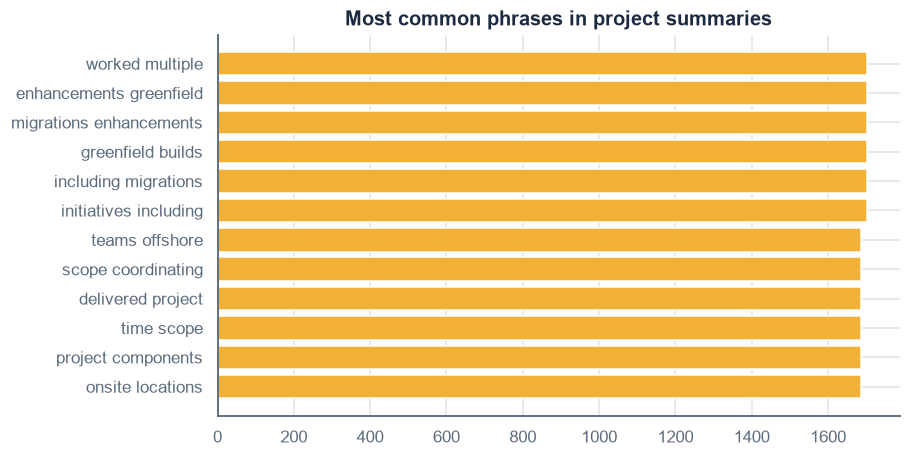

In [13]:
# Most common two-word phrases in project summaries
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(stop_words="english", ngram_range=(2, 2))
counts = cv.fit_transform(df["project_summary_clean"]).sum(axis=0).A1
bigrams = pd.Series(counts, index=cv.get_feature_names_out()).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(bigrams.index[::-1], bigrams.values[::-1], color=COLORS["mustard"])
ax.set_title("Most common phrases in project summaries")
save(fig, "02_project_bigrams")
plt.show()

The summaries are template-like (e.g. *"cross functional teams"*, *"delivered project components"*). They confirm domain
and seniority but carry little extra detail — another reason to treat text similarity as a **supporting** signal.

## 7. Resume quality indicators

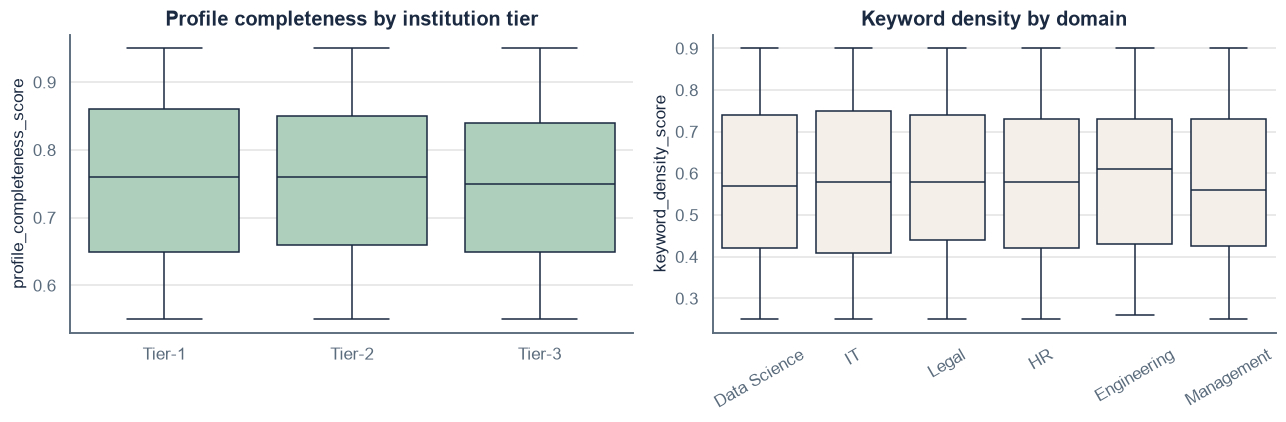

In [14]:
# Keyword density and completeness by institution tier and by domain
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="institution_tier", y="profile_completeness_score", ax=axes[0],
            order=["Tier-1", "Tier-2", "Tier-3"], color=COLORS["mint"], linecolor=COLORS["ink"])
axes[0].set_title("Profile completeness by institution tier")
sns.boxplot(data=df, x="primary_domain", y="keyword_density_score", ax=axes[1],
            color=COLORS["sand"], linecolor=COLORS["ink"])
axes[1].set_title("Keyword density by domain")
axes[1].tick_params(axis="x", rotation=30)
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
save(fig, "02_quality_scores")
plt.show()

## 8. Hypothesis testing
Statistical tests check whether patterns seen in the charts are real or could be due to chance (α = 0.05).

In [15]:
from scipy import stats

results = []

# H1: Does profile completeness differ by institution tier? (one-way ANOVA)
groups = [g["profile_completeness_score"].values for _, g in df.groupby("institution_tier")]
f, p = stats.f_oneway(*groups)
results.append(["H1", "Profile completeness differs by institution tier", "One-way ANOVA", round(f, 3), p])

# H2: Do candidates with management experience have more years? (Mann-Whitney U, no normality needed)
mgr = df.loc[df["management_experience_flag"] == 1, "years_experience"]
non = df.loc[df["management_experience_flag"] == 0, "years_experience"]
u, p = stats.mannwhitneyu(mgr, non, alternative="greater")
results.append(["H2", f"Managers have more experience (median {mgr.median():.0f} vs {non.median():.0f} yrs)", "Mann-Whitney U", round(u, 1), p])

# H3: Is institution tier linked to domain? (chi-square test of independence)
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["primary_domain"], df["institution_tier"]))
results.append(["H3", "Institution tier depends on domain", "Chi-square", round(chi2, 3), p])

# H4: Do resumes with skill typos have a different keyword density? (Welch t-test)
typo = df.loc[df["skill_typo_flag"] == 1, "keyword_density_score"]
clean = df.loc[df["skill_typo_flag"] == 0, "keyword_density_score"]
t, p = stats.ttest_ind(typo, clean, equal_var=False)
results.append(["H4", "Keyword density differs for resumes with skill typos", "Welch t-test", round(t, 3), p])

# H5: Is years of experience different across domains? (Kruskal-Wallis)
h, p = stats.kruskal(*[g["years_experience"].values for _, g in df.groupby("primary_domain")])
results.append(["H5", "Years of experience differ across domains", "Kruskal-Wallis", round(h, 3), p])

tests = pd.DataFrame(results, columns=["id", "hypothesis (H1 side)", "test", "statistic", "p_value"])
tests["significant at 5%"] = np.where(tests["p_value"] < 0.05, "Yes", "No")
tests["p_value"] = tests["p_value"].map(lambda v: f"{v:.4f}" if v >= 0.0001 else "<0.0001")
tests.to_csv(OUTPUTS / "hypothesis_tests.csv", index=False)
tests

,id,hypothesis (H1 side),test,statistic,p_value,significant at 5%
0,H1,Profile completeness differs by institution tier,One-way ANOVA,2.804,0.0607,No
1,H2,Managers have more experience (median 10 vs 4 yrs),Mann-Whitney U,5937519.000,<0.0001,Yes
2,H3,Institution tier depends on domain,Chi-square,12.049,0.2818,No
3,H4,Keyword density differs for resumes with skill typos,Welch t-test,0.677,0.4987,No
4,H5,Years of experience differ across domains,Kruskal-Wallis,221.532,<0.0001,Yes


### What the tests tell us
- **H1 / H3 – institution tier:** tier is *not* linked to profile completeness or domain. Tier therefore adds no
  information about job fit, and using it could add **pedigree bias**. ➜ Tier is **excluded** from the fit score and only used for a fairness check.
- **H2 – managers are more experienced:** strongly significant. Leadership flags and years overlap, which supports
  combining them into one *leadership score* rather than counting each separately.
- **H4 – typos vs keyword density:** no difference, so typos are a parsing/format issue, not a sign of weaker candidates —
  candidates should not be penalised for them (our fuzzy cleaning handles them).
- **H5 – experience by domain:** domains have different experience profiles (Management is the most senior), so experience
  must be judged **relative to each job's range**, not with one global cut-off.

## 9. Key EDA takeaways for the matching engine
1. **Skills are the strongest differentiator** inside a domain → mandatory/optional skill matching is the core feature.
2. **Experience and seniority are clean and consistent** → a job-specific experience range fit is reliable.
3. **Leadership / delivery flags cluster together** → group them into exposure scores.
4. **Text summaries are templated** → NLP similarity is a supporting signal, not the main driver.
5. **Institution tier carries no fit signal** → leave it out of scoring to avoid bias.